# 차원 축소 — 차원의 저주 · 주성분 분석(PCA)

수업 필기 `PCA실습` 과 메모(`1일_비지도학습_K_Means.txt` 의 PCA 부분)를 **실행 가능하도록 정리 · 개선한 노트**입니다.
(교재 `머신러닝` v6 p.115~120 — 14. 차원 축소)

- 원본에서 고친 부분은 **📝 고친 부분** 으로 따로 적어 두었습니다.
- 그림 · **애니메이션(GIF)** 은 [`images/`](./images/) 폴더에 미리 만들어 두었습니다.
- 같은 날 배운 AutoML 은 [`automl_autogluon.ipynb`](./automl_autogluon.ipynb), 비지도 학습(K-Means)은 [`kmeans_clustering.ipynb`](./kmeans_clustering.ipynb) 에 정리했습니다.

> 손글씨 숫자 데이터는 `sklearn.datasets.load_digits()` 로 바로 불러오므로 CSV 가 필요 없습니다.

In [1]:
# 그래프 한글 폰트 설정 (운영체제별)
import platform
import matplotlib.pyplot as plt

if platform.system() == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'
elif platform.system() == 'Darwin':
    plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False

## 1. 차원 = 특성(컬럼)의 개수

| 특성 수 | 차원 | 예 |
|---|---|---|
| 1개 | 1차원 (직선) | 키 |
| 2개 | 2차원 (평면) | 키, 몸무게 |
| 3개 | 3차원 (공간) | 키, 몸무게, 나이 |
| 64개 | 64차원 | 8×8 손글씨 이미지의 픽셀 64개 |

### 차원의 저주 (Curse of Dimensionality, 교재 p.116)

차원이 늘어나면 **공간의 부피가 기하급수적으로 커져서** 같은 개수의 데이터가 **텅 빈 공간에 흩어진다(희박, sparse)**.

1. **과대적합 위험** — 샘플 수에 비해 특성이 많으면 모델이 **잡음(노이즈)까지 외운다**
2. **거리가 무의미해짐** — 고차원에서는 모든 점 사이의 거리가 **비슷비슷해져서**, 유클리드 거리로 판단하는 알고리즘(**SVM · KNN · K-Means**)의 성능이 떨어진다

해결 방법은 ① 데이터를 엄청나게 더 모으기(현실적으로 불가능) ② **차원 축소**.

In [2]:
import numpy as np

# 같은 500개의 점을 차원만 바꿔 [0, 1] 범위에 무작위로 뿌린다
rng = np.random.default_rng(0)

print(f"{'차원':>6} | {'가장 가까운 점':>10} | {'가장 먼 점':>8} | (먼 - 가까운) / 가까운")
for d in [2, 10, 100, 1000]:
    X = rng.random((500, d))
    dist = np.sqrt(((X[1:] - X[0]) ** 2).sum(axis=1))   # 0번 점에서 나머지 499개까지의 유클리드 거리
    ratio = (dist.max() - dist.min()) / dist.min()
    print(f"{d:>6} | {dist.min():>14.3f} | {dist.max():>10.3f} | {ratio:.2f}")

    차원 |   가장 가까운 점 |   가장 먼 점 | (먼 - 가까운) / 가까운
     2 |          0.014 |      0.937 | 66.13
    10 |          0.578 |      1.918 | 2.32
   100 |          3.634 |      4.953 | 0.36


  1000 |         12.295 |     13.618 | 0.11


2차원에서는 가장 먼 점이 가장 가까운 점보다 **약 67배** 멀지만, 1000차원에서는 **1.11배** — 거의 같다.
"가까운 이웃"이라는 개념 자체가 흐려지는 것이 **거리의 무의미화**다.

![차원의 저주 애니메이션](./images/anim_01_curse_of_dimensionality.gif)

🎬 점 1,000개로 차원을 2 → 1000 으로 늘리면서 **0번 점에서 다른 점까지 거리의 분포**를 그렸다(차원마다 평균 거리를 1 로 맞춰 비교). 2차원에서는 거리가 0 근처부터 2 넘게까지 넓게 퍼지지만, 차원이 커질수록 막대가 **1 근처 한 곳으로 몰린다** — 모든 점이 비슷하게 멀다. 오른쪽은 (가장 먼 거리 ÷ 가장 가까운 거리).

> **📝 고친 부분** (메모)
> - "과대적합 … 유클리드 기반 알고리즘" → 과대적합(잡음까지 학습)과 **거리의 무의미화**(유클리드 거리 기반 알고리즘 성능 저하)는 차원의 저주가 만드는 **서로 다른 두 문제**라 나눠 적었다.
> - "차원이 늘어나면 공간 낭비" → 정확히는 공간이 커져서 **데이터 밀도가 희박해지는 것**.

## 2. PCA 원리 — 가장 넓게 퍼진 방향으로 투영 (교재 p.117~119)

- **선형 축소**: 고차원 점들을 더 낮은 차원의 평평한 공간(직선 · 평면)에 **수직으로 투영**한다.
- **PC1 (첫 번째 주성분)**: 데이터의 **분산이 가장 큰** 방향
- **PC2**: PC1 과 **직교(90°)** 하면서 남은 분산이 가장 큰 방향 → PC3, PC4 … 도 같은 방식
- 주성분은 원래 특성 수만큼 만들 수 있고, 그중 **앞의 몇 개만 남기는 것**이 차원 축소다.

> 분산이 크다 = 점들이 그 방향으로 넓게 퍼져 있다 = 그 방향이 **데이터 사이의 차이(정보)를 가장 많이 담고 있다**.

In [3]:
from sklearn.decomposition import PCA

# 상관관계가 강한 2차원 데이터 200개 (x1 이 크면 x2 도 큼)
rng = np.random.default_rng(1)
x1 = rng.normal(0, 2, 200)
x2 = 0.8 * x1 + rng.normal(0, 0.7, 200)
X_2d = np.column_stack([x1, x2])

pca_1 = PCA(n_components=1)                 # 2차원 -> 1차원
z = pca_1.fit_transform(X_2d)               # 각 점의 PC1 좌표 (투영된 위치)

print("원본 모양 :", X_2d.shape, "-> 축소 후 :", z.shape)
print("PC1 방향 (단위 벡터) :", pca_1.components_[0].round(3))
print("PC1 각도 :", round(float(np.degrees(np.arctan2(*pca_1.components_[0][::-1]))), 1), "도")
print("PC1 이 담은 정보(분산) 비율 :", round(float(pca_1.explained_variance_ratio_[0]), 3))

원본 모양 : (200, 2) -> 축소 후 : (200, 1)
PC1 방향 (단위 벡터) : [0.754 0.657]
PC1 각도 : 41.1 도
PC1 이 담은 정보(분산) 비율 : 0.962


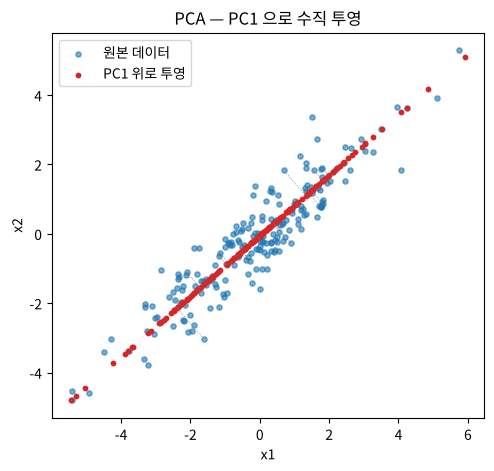

In [4]:
# 투영된 점을 다시 2차원 좌표로 되돌리면(inverse_transform) PC1 직선 위에 놓인다
X_back = pca_1.inverse_transform(z)

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(X_2d[:, 0], X_2d[:, 1], s=14, alpha=0.6, label='원본 데이터')
ax.scatter(X_back[:, 0], X_back[:, 1], s=10, color='tab:red', label='PC1 위로 투영')
for a, b in zip(X_2d[::8], X_back[::8]):
    ax.plot([a[0], b[0]], [a[1], b[1]], color='gray', lw=0.6, ls=':')   # 수직 투영선
ax.set_aspect('equal')
ax.set_xlabel('x1'); ax.set_ylabel('x2'); ax.set_title('PCA — PC1 으로 수직 투영')
ax.legend()
plt.show()

![PCA 투영 애니메이션](./images/anim_02_pca_projection.gif)

🎬 투영할 축을 0° → 180° 로 돌리면서 **투영된 점들의 분산**을 오른쪽에 그렸다. 분산이 **가장 커지는 각도가 바로 PC1**(sklearn 이 계산한 각도와 일치), 그 각도에서 90° 돌린 방향이 PC2 다. 축이 데이터와 엇갈릴수록 투영선(점선)이 길어지고 = 잃어버리는 정보가 많아진다.

> **📝 고친 부분** (메모)
> - "(경계선과 마진)" 은 **SVM**, "엔트로픽 느낌" 은 **결정 트리(엔트로피)** 개념이다. PCA 는 정답(레이블) 없이 **분산**만 보고 축을 찾는다.
> - "데이터를 X (PC1), Y (PC2) 로 내리면서" → PC1 · PC2 는 원래의 x축 · y축이 아니라 **데이터가 가장 넓게 퍼진 새 축**이다(위 예에서는 약 41° 기울어진 대각선).

## 3. 실습 — 64차원 손글씨 이미지를 2차원으로 (교재 p.120)

`load_digits()` : 0~9 손글씨 숫자 **1,797장**, 각 이미지는 **8×8 = 64 픽셀** → 특성 64개 = **64차원**.

In [5]:
from sklearn.datasets import load_digits

digits = load_digits()
X_data = digits.data       # (1797, 64) — 픽셀 64개
y_data = digits.target     # 정답 숫자 0~9 (PCA 에는 사용하지 않음, 그림 색칠용)

print("모양 :", X_data.shape)
print("픽셀 값 범위 :", X_data.min(), "~", X_data.max())

# 숫자별 개수 — 거의 균등 (174 ~ 183장)
values, counts = np.unique(y_data, return_counts=True)
print("숫자별 개수 :", dict(zip(values.tolist(), counts.tolist())))

모양 : (1797, 64)
픽셀 값 범위 : 0.0 ~ 16.0
숫자별 개수 : {0: 178, 1: 182, 2: 177, 3: 183, 4: 181, 5: 182, 6: 181, 7: 179, 8: 174, 9: 180}


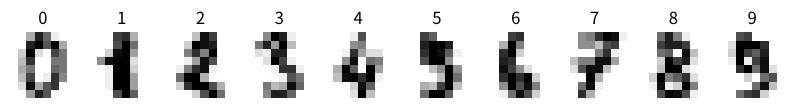

In [6]:
# 처음 10장 보기 — 8x8 로 다시 접으면 이미지가 된다
fig, axes = plt.subplots(1, 10, figsize=(10, 1.6))
for ax, img, label in zip(axes, digits.images, y_data):
    ax.imshow(img, cmap='gray_r')     # gray_r : 값이 클수록 검게
    ax.set_title(label); ax.axis('off')
plt.show()

> **📝 고친 부분** (`PCA실습`)
> - 주석 `MAX(검정):255 , MIN(흰색):0` → `load_digits` 의 픽셀 값은 **0 ~ 16** 이다(원본 32×32 흑백 이미지를 4×4 칸씩 묶어 **검은 픽셀 수를 센 값**). 255 는 일반적인 8비트 이미지 기준.
> - `#print(...)` 로 막혀 있던 모양 · 숫자별 개수 출력을 살렸다.

### 3-1. 시각화 목적 — 64차원 → 2차원 (`n_components=2`, 정수 = 주성분 개수)

In [7]:
pca_2d = PCA(n_components=2, random_state=0)     # 정수(int) → 남길 주성분 개수
X_data_2d = pca_2d.fit_transform(X_data)          # 64차원 -> 2차원

print(f"(전) : {X_data.shape}  ->  (후) : {X_data_2d.shape}")
print("PC1, PC2 가 담은 정보 비율 :", pca_2d.explained_variance_ratio_.round(3))
print("합계 :", round(float(pca_2d.explained_variance_ratio_.sum()), 3))
X_data_2d[:5]

(전) : (1797, 64)  ->  (후) : (1797, 2)
PC1, PC2 가 담은 정보 비율 : [0.149 0.136]
합계 : 0.285


array([[ -1.25946645, -21.27488348],
       [  7.9576113 ,  20.76869896],
       [  6.99192297,   9.95598641],
       [-15.90610526,  -3.33246429],
       [ 23.30686741,  -4.26906083]])

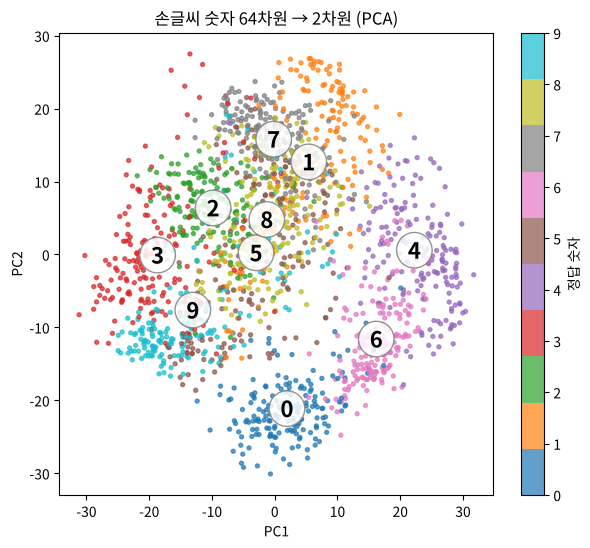

In [8]:
# 2차원으로 줄인 1,797개 점을 정답 숫자별 색으로 (PCA 는 정답을 보지 않았다)
fig, ax = plt.subplots(figsize=(7, 6))
sc = ax.scatter(X_data_2d[:, 0], X_data_2d[:, 1], c=y_data, cmap='tab10', s=8, alpha=0.7)
for d in range(10):                                   # 숫자별 중심에 숫자 표시
    cx, cy = X_data_2d[y_data == d].mean(axis=0)
    ax.text(cx, cy, str(d), fontsize=16, weight='bold', ha='center', va='center',
            bbox=dict(boxstyle='circle', fc='white', ec='gray', alpha=0.85))
ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
ax.set_title('손글씨 숫자 64차원 → 2차원 (PCA)')
plt.colorbar(sc, ax=ax, label='정답 숫자')
plt.show()

![digits PCA 2D](./images/00_digits_pca_2d.png)

- 0 · 4 · 6 · 3 은 비교적 따로 모이지만, 1 · 7 · 8 · 9 · 5 는 **가운데에서 겹친다**.
- 2차원은 원래 정보의 **28.5%** 만 담는다 → 그림으로 **"대략 이렇게 생겼다"** 를 보는 데는 좋지만, 이 2개로 분류 모델을 만들면 성능이 크게 떨어진다(아래 5장).

> 필기에서는 `plotly.express` 를 임포트만 하고 그림은 그리지 않았다. GitHub 미리보기에서도 보이도록 matplotlib 로 그렸다.

### 3-2. 원본 정보의 95% 유지 (`n_components=0.95`, 실수 = 보존할 정보 비율)

| `n_components` 값 | 의미 |
|---|---|
| **정수** `2` | 주성분을 **2개** 남긴다 |
| **실수** `0.95` (0~1) | 누적 정보 비율이 **95% 이상**이 될 때까지 주성분을 남긴다 → 개수는 PCA 가 결정 |

교재(p.119) 기준 : 시각화는 **2개**, 모델 학습용은 원래 정보의 **80~90% 이상**을 유지하는 개수.

In [9]:
import pandas as pd

pca_95 = PCA(n_components=0.95, random_state=0)   # 실수(float) → 정보 95% 보존
X_data_95 = pca_95.fit_transform(X_data)

print("남은 주성분 개수 :", pca_95.n_components_, "개  (64 -> 29)")
print("보존된 정보 :", round(float(pca_95.explained_variance_ratio_.sum()), 4))

df_95 = pd.DataFrame(X_data_95, columns=[f'PC{i + 1}' for i in range(pca_95.n_components_)])
df_95.head()

남은 주성분 개수 : 29 개  (64 -> 29)
보존된 정보 : 0.9548


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,...,PC20,PC21,PC22,PC23,PC24,PC25,PC26,PC27,PC28,PC29
0,-1.259466,-21.274883,9.463055,-13.014189,7.128823,7.440659,-3.252837,-2.553470,0.581842,-3.625697,...,3.462119,2.680850,1.009450,2.009703,1.295315,1.178879,2.300582,3.670721,0.943669,1.132502
1,7.957611,20.768699,-4.439506,14.893664,-5.896249,6.485622,-2.126228,4.615936,-3.587450,1.074705,...,5.255708,-1.205777,-4.838902,0.860251,-2.974439,5.288817,0.119213,2.182618,0.510227,-2.313549
2,6.991923,9.955986,-2.958558,12.288302,18.126023,4.507664,-1.843122,16.415200,-0.719233,-4.255805,...,-8.731076,4.951115,-2.465109,5.999388,0.105727,-3.062671,0.166046,4.228821,-2.157657,-0.837958
3,-15.906105,-3.332464,-9.824372,12.275838,-6.965169,-1.089483,1.042085,-10.973556,3.259735,-6.498753,...,3.876889,0.269413,3.623236,2.538124,-1.354896,-1.740973,-1.340244,-5.846014,-4.682220,1.113042
4,23.306867,-4.269061,5.675129,13.851524,0.358124,2.857574,0.720497,-13.041696,3.835413,-13.414164,...,-5.035236,0.206830,5.740696,-7.611946,3.991408,2.781007,-0.166739,0.484305,-0.627979,3.287348


정보 50% 이상 → 주성분  5개
정보 80% 이상 → 주성분 13개
정보 90% 이상 → 주성분 21개
정보 95% 이상 → 주성분 29개
정보 99% 이상 → 주성분 41개


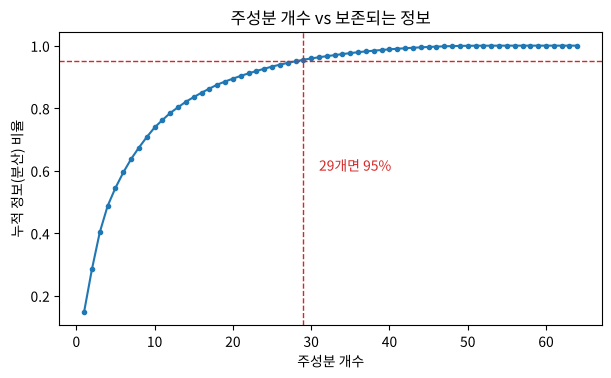

In [10]:
# 주성분을 전부(64개) 구해서 누적 정보 비율 곡선 그리기
pca_full = PCA().fit(X_data)
cum = np.cumsum(pca_full.explained_variance_ratio_)

for t in [0.5, 0.8, 0.9, 0.95, 0.99]:
    print(f"정보 {t:.0%} 이상 → 주성분 {int(np.argmax(cum >= t)) + 1:>2}개")

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(range(1, 65), cum, marker='o', ms=3)
ax.axhline(0.95, color='tab:red', ls='--', lw=1)
ax.axvline(29, color='tab:red', ls='--', lw=1)
ax.text(31, 0.6, '29개면 95%', color='tab:red')
ax.set_xlabel('주성분 개수'); ax.set_ylabel('누적 정보(분산) 비율')
ax.set_title('주성분 개수 vs 보존되는 정보')
plt.show()

앞쪽 주성분 몇 개가 정보를 대부분 가져가고, 뒤로 갈수록 거의 0 이다(64개 중 **3개는 정보 0** — 가장자리 픽셀 3개가 모든 이미지에서 항상 0).
→ 뒤쪽 주성분 = **노이즈에 가까운 컬럼**을 버리는 것이 PCA 의 핵심.

> **📝 고친 부분** (`PCA실습`)
> - 95% 결과를 `pd.DataFrame(data=X_data_95)` 로 만들면 컬럼 이름이 `0, 1, 2 …` → `PC1 … PC29` 로 이름을 붙였다.
> - `random_state=0` 은 `svd_solver='randomized'` 일 때만 결과에 영향을 준다. 이 데이터 크기에서는 기본값(`'auto'` → 정확한 계산)이 쓰이므로 있어도 없어도 결과가 같다.

## 4. 줄인 데이터로 이미지를 되돌리면 — `inverse_transform`

주성분 k 개만 남겼다가 64차원으로 **되돌리면(복원)**, 버린 정보만큼 이미지가 흐려진다.

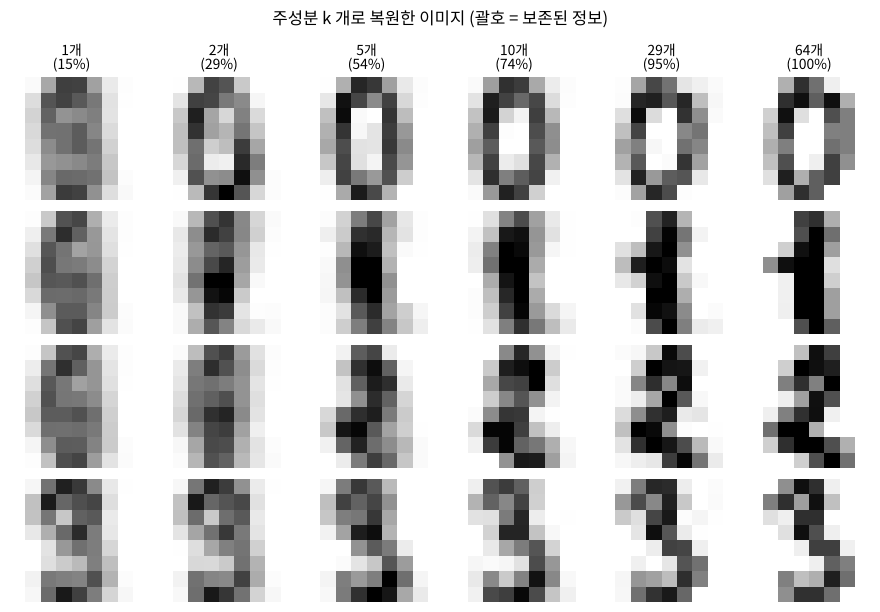

In [11]:
fig, axes = plt.subplots(4, 6, figsize=(9, 6.2))
sample_idx = [0, 1, 2, 3]                         # 숫자 0, 1, 2, 3
for col, k in enumerate([1, 2, 5, 10, 29, 64]):
    pca_k = PCA(n_components=k).fit(X_data)
    X_rec = pca_k.inverse_transform(pca_k.transform(X_data[sample_idx]))
    for row, img in enumerate(X_rec):
        ax = axes[row, col]
        ax.imshow(img.reshape(8, 8), cmap='gray_r', vmin=0, vmax=16)
        ax.axis('off')
        if row == 0:
            ax.set_title(f'{k}개\n({np.cumsum(pca_full.explained_variance_ratio_)[k - 1]:.0%})', fontsize=10)
plt.suptitle('주성분 k 개로 복원한 이미지 (괄호 = 보존된 정보)')
plt.tight_layout()
plt.show()

![PCA 복원 애니메이션](./images/anim_03_pca_reconstruction.gif)

🎬 주성분을 1개 → 64개로 늘려 가며 같은 숫자 10장을 복원했다. 주성분 **10개(74%)** 쯤이면 사람이 숫자를 알아보고, **29개(95%)** 면 원본과 거의 같다.

## 5. 실전 — 차원을 줄여도 모델 성능이 유지될까?

KNN(가까운 이웃 5개의 다수결) 분류기로 비교. **PCA 도 학습용 데이터로만 `fit`** 해야 하므로(스케일러와 같은 규칙) `make_pipeline` 으로 묶었다.

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline

X_train, X_test, y_train, y_test = train_test_split(
    X_data, y_data, test_size=0.2, random_state=0, stratify=y_data)

print(f"{'특성 수':>8} | 평가용 정확도")
for k in [64, 29, 10, 2]:
    if k == 64:
        model = KNeighborsClassifier()                                   # PCA 없이 원본 64개
    else:
        model = make_pipeline(PCA(n_components=k, random_state=0),       # 학습용으로만 fit
                              KNeighborsClassifier())
    model.fit(X_train, y_train)
    print(f"{k:>8} | {model.score(X_test, y_test):.4f}")

    특성 수 | 평가용 정확도
      64 | 0.9778
      29 | 0.9750
      10 | 0.9611
       2 | 0.6167


| 특성 수 | 보존 정보 | KNN 정확도 |
|---|---|---|
| 64 (원본) | 100% | **0.978** |
| 29 | 95% | **0.975** |
| 10 | 74% | 0.961 |
| 2 | 28.5% | 0.617 |

특성을 **64 → 29개(절반 이하)** 로 줄여도 정확도는 0.3%p 만 떨어진다. 2개는 그림용이지 학습용이 아니다.

### 정리

| | |
|---|---|
| 목적 | 쓸모없는 공간(희박한 고차원) · 노이즈 컬럼을 줄여 **과대적합 방지 · 계산 속도 · 시각화** |
| 방법 | 분산이 가장 큰 방향(PC1) → 그와 직교하며 다음으로 큰 방향(PC2) … 으로 투영 |
| `n_components` | 정수 = 주성분 개수 / 실수(0~1) = 보존할 정보 비율 |
| 주의 | 학습용으로만 `fit` · 단위가 다른 특성이면 **스케일링 후 PCA** · 주성분은 원래 컬럼이 아니라 **섞인 새 축**이라 해석이 어렵다 |